# Линейная регрессия со Scikit-learn — машинное обучение на Python

Этот урок входит в [интенсив по Data Science с нуля от Jovian](https://zerotodatascience.com) и курс [«Машинное обучение на Python: от нуля до GBM»](https://jovian.ai/learn/machine-learning-with-python-zero-to-gbms).

![](https://i.imgur.com/1EzyZvj.png)


В этом уроке рассматриваются следующие темы:

- Типичная постановка задачи машинного обучения
- Загрузка и исследование набора данных для машинного обучения
- Линейная регрессия с одной переменной с помощью Scikit-learn
- Линейная регрессия с несколькими переменными
- Использование категориальных признаков в машинном обучении
- Коэффициенты регрессии и важность признаков
- Другие модели и методы регрессии в Scikit-learn
- Применение линейной регрессии к другим наборам данных

### Как запустить код

Этот урок представляет собой исполняемый [ноутбук Jupyter](https://jupyter.org), размещённый на [Jovian](https://www.jovian.ai). Вы можете _запустить_ его и поэкспериментировать с примерами кода двумя способами: *с помощью бесплатных онлайн-сервисов* (рекомендуется) или *на своём компьютере*.

#### Способ 1. Запуск с помощью бесплатных онлайн-сервисов (в один клик, рекомендуется)

Самый простой способ запустить код — нажать кнопку **Run** («Запустить») в верхней части страницы и выбрать **Run on Binder** («Запустить в Binder»). Также можно выбрать «Run on Colab» («Запустить в Colab») или «Run on Kaggle» («Запустить в Kaggle»), но для работы с этими платформами потребуется создать учётную запись в [Google Colab](https://colab.research.google.com) или [Kaggle](https://kaggle.com).

#### Способ 2. Локальный запуск на своём компьютере

Чтобы запустить код на своём компьютере, установите [Python](https://www.python.org), скачайте ноутбук и установите необходимые библиотеки. Рекомендуем использовать дистрибутив Python [Conda](https://docs.conda.io/projects/conda/en/latest/user-guide/install/). Нажмите кнопку **Run** («Запустить») в верхней части страницы, выберите **Run Locally** («Запустить локально») и следуйте инструкциям.

> **Ноутбуки Jupyter**: этот урок — [ноутбук Jupyter](https://jupyter.org), то есть документ, состоящий из _ячеек_. Каждая ячейка может содержать код на Python или текстовые пояснения. Вы можете выполнять ячейки с кодом и сразу видеть результаты в ноутбуке: числа, сообщения, графики, таблицы, файлы и многое другое. Jupyter — мощная платформа для экспериментов и анализа. Не бойтесь менять код и допускать ошибки: находя и исправляя их, вы многому научитесь. Чтобы очистить все результаты и начать выполнение с начала, выберите «Kernel > Restart & Clear Output» («Ядро > Перезапустить и очистить результаты»).

## Постановка задачи

Этот урок построен на практической работе с кодом. Сначала мы определим понятия _машинного обучения_ и _линейной регрессии_ на примере конкретной задачи, а затем обобщим эти определения. Мы последовательно разберём типичную задачу машинного обучения:

> **ЗАДАЧА**: компания ACME Insurance Inc. предлагает доступное медицинское страхование тысячам клиентов по всей территории США. Вы — ведущий специалист по Data Science в ACME, и **вам поручено создать автоматизированную систему оценки годовых медицинских расходов новых клиентов** на основе таких сведений, как возраст, пол, BMI, число детей, курение и регион проживания.
>
> Оценки вашей системы будут использоваться для определения годовой страховой премии (суммы, выплачиваемой ежемесячно), предлагаемой клиенту. В соответствии с требованиями регулирующих органов вы должны уметь объяснить, почему система выдаёт тот или иной прогноз.
>
> Вам предоставлен [CSV-файл](https://raw.githubusercontent.com/JovianML/opendatasets/master/data/medical-charges.csv) с проверенными историческими данными: перечисленными выше сведениями и фактическими медицинскими расходами более чем 1300 клиентов.
> <img src="https://i.imgur.com/87Uw0aG.png" width="480">
>
> Источник набора данных: https://github.com/stedy/Machine-Learning-with-R-datasets

**ЗАДАНИЕ**: прежде чем продолжить, подумайте, как можно подойти к решению этой задачи. Запишите ниже не менее пяти идей:

1. ???
2. ???
3. ???
4. ???
5. ???

## Загрузка данных

Сначала загрузим данные с помощью функции `urlretrieve` из `urllib.request`.

In [160]:
medical_charges_url = 'https://raw.githubusercontent.com/JovianML/opendatasets/master/data/medical-charges.csv'

In [161]:
from urllib.request import urlretrieve

In [162]:
from pathlib import Path

if not Path('medical.csv').exists():
    urlretrieve(medical_charges_url, 'medical.csv')

Теперь создадим DataFrame Pandas из загруженного файла, чтобы просмотреть и проанализировать данные.

In [163]:
import pandas as pd

In [164]:
medical_df = pd.read_csv('medical.csv')

In [165]:
medical_df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


Набор данных содержит 1338 строк и 7 столбцов. Каждая строка содержит сведения об одном клиенте.

Наша цель — найти способ оценивать значение в столбце «charges» по значениям остальных столбцов. Если это удастся сделать для исторических данных, мы сможем оценивать расходы и для новых клиентов: достаточно будет узнать их возраст, пол, BMI, число детей, сведения о курении и регион проживания.

Проверим тип данных каждого столбца.

In [166]:
medical_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


Как видим, «age», «children», «bmi» ([индекс массы тела](https://en.wikipedia.org/wiki/Body_mass_index)) и «charges» содержат числа, а «sex», «smoker» и «region» — строки, вероятно обозначающие категории. Пропущенных значений нет ни в одном столбце, что заметно упрощает работу!

Посмотрим на описательные статистики числовых столбцов:

In [167]:
medical_df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Диапазоны значений числовых столбцов тоже выглядят разумно: например, отрицательного возраста нет. Поэтому, возможно, серьёзная очистка или исправление данных не потребуются. Однако распределение столбца «charges» выглядит сильно асимметричным: медиана (50-й процентиль) значительно ниже максимального значения.

> **ЗАДАНИЕ**: какие ещё выводы можно сделать по таблице выше? Запишите их ниже:
>
> 1. ???
> 2. ???
> 3. ???
> 4. ???
> 5. ???

Сохраним работу, прежде чем продолжить.

## Разведочный анализ и визуализация

Исследуем данные: визуализируем распределения значений некоторых столбцов и зависимости между «charges» и другими столбцами.

Для визуализации будем использовать Matplotlib, Seaborn и Plotly. Освоить эти библиотеки помогут следующие уроки:

- https://jovian.ai/aakashns/python-matplotlib-data-visualization
- https://jovian.ai/aakashns/interactive-visualization-plotly
- https://jovian.ai/aakashns/dataviz-cheatsheet

In [168]:
import plotly.express as px
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import json

with open('plotly-ru.json', encoding='utf-8') as file:
    plotly_config = {'locale': 'ru', 'locales': {'ru': json.load(file)}}

Следующие настройки улучшат стандартное оформление графиков и размеры шрифтов.

In [169]:
sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (10, 6)
matplotlib.rcParams['figure.facecolor'] = '#00000000'
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

plot_labels = {
    'age': 'Возраст', 'bmi': 'BMI', 'children': 'Число детей',
    'charges': 'Медицинские расходы', 'smoker': 'Курение',
    'sex': 'Пол', 'region': 'Регион', 'count': 'Число клиентов'
}
category_labels = {
    'yes': 'Курит', 'no': 'Не курит', 'male': 'Мужской', 'female': 'Женский',
    'northeast': 'Северо-восток', 'northwest': 'Северо-запад',
    'southeast': 'Юго-восток', 'southwest': 'Юго-запад'
}
feature_labels = {
    'age': 'Возраст', 'bmi': 'BMI', 'children': 'Число детей',
    'smoker': 'Курение', 'sex': 'Пол', 'region': 'Регион',
    'smoker_code': 'Курение', 'sex_code': 'Пол',
    'smoker_yes': 'Курение: курит', 'sex_male': 'Пол: мужской',
    'northeast': 'Северо-восток', 'northwest': 'Северо-запад',
    'southeast': 'Юго-восток', 'southwest': 'Юго-запад',
    'region_northwest': 'Регион: северо-запад',
    'region_southwest': 'Регион: юго-запад',
    'region_southeast': 'Регион: юго-восток', '1': 'Свободный член'
}

### Возраст

Возраст — числовой признак. Минимальный возраст в наборе данных — 18 лет, максимальный — 64 года. Поэтому распределение возраста можно показать с помощью гистограммы с 47 интервалами (по одному на каждый год) и диаграммы размаха («ящик с усами»). Мы используем Plotly, чтобы сделать график интерактивным, но аналогичные графики можно построить и с помощью Seaborn.

In [170]:
medical_df.age.describe()

count    1338.000000
mean       39.207025
std        14.049960
min        18.000000
25%        27.000000
50%        39.000000
75%        51.000000
max        64.000000
Name: age, dtype: float64

In [171]:
fig = px.histogram(medical_df, labels=plot_labels, 
                   x='age', 
                   marginal='box', 
                   nbins=47, 
                   title='Распределение возраста')
fig.update_layout(bargap=0.1)
fig.update_layout(font_family='Arial')
fig.update_yaxes(title_text='Число клиентов', row=1, col=1)
for trace in fig.data:
    if trace.hovertemplate:
        trace.hovertemplate = trace.hovertemplate.replace('count=', 'Число клиентов=')
fig.show(config=plotly_config)

Возраст в наборе данных распределён почти равномерно: каждому возрасту соответствуют 20–30 клиентов. Исключение составляют 18 и 19 лет: клиентов этих возрастов, по-видимому, более чем вдвое больше, чем клиентов других возрастов. Такое распределение может объясняться тем, что [численность людей каждого возраста](https://www.statista.com/statistics/241488/population-of-the-us-by-sex-and-age/) от 18 до 64 лет в США различается незначительно.

> **ЗАДАНИЕ**: можете ли вы объяснить, почему клиентов в возрасте 18 и 19 лет более чем вдвое больше, чем клиентов других возрастов?
>
> ???

### Индекс массы тела

Посмотрим на распределение BMI (индекса массы тела) клиентов с помощью гистограммы и диаграммы размаха.

In [172]:
fig = px.histogram(medical_df, labels=plot_labels, 
                   x='bmi', 
                   marginal='box', 
                   color_discrete_sequence=['red'], 
                   title='Распределение BMI (индекса массы тела)')
fig.update_layout(bargap=0.1)
fig.update_layout(font_family='Arial')
fig.update_yaxes(title_text='Число клиентов', row=1, col=1)
for trace in fig.data:
    if trace.hovertemplate:
        trace.hovertemplate = trace.hovertemplate.replace('count=', 'Число клиентов=')
fig.show(config=plotly_config)

Значения индекса массы тела, по-видимому, образуют [нормальное распределение](https://en.wikipedia.org/wiki/Normal_distribution) с центром около 30 и несколькими выбросами справа. Значения BMI можно интерпретировать следующим образом ([источник](https://study.com/academy/lesson/what-is-bmi-definition-formula-calculation.html)):

![](https://i.imgur.com/lh23OiY.jpg)

> **ЗАДАНИЕ**: можете ли вы объяснить, почему возраст распределён равномерно, а BMI — по нормальному закону?
>
> ???

### Медицинские расходы

Визуализируем распределение «charges», то есть годовых медицинских расходов клиентов. Именно значения этого столбца мы пытаемся прогнозировать. Также используем категориальный столбец «smoker», чтобы различать расходы курящих и некурящих клиентов.

In [173]:
fig = px.histogram(medical_df, labels=plot_labels, 
                   x='charges', 
                   marginal='box', 
                   color='smoker', 
                   color_discrete_sequence=['green', 'grey'], 
                   title='Годовые медицинские расходы')
fig.update_layout(bargap=0.1)
fig.update_layout(font_family='Arial')
fig.update_yaxes(title_text='Число клиентов', row=1, col=1)
for trace in fig.data:
    if trace.hovertemplate:
        trace.hovertemplate = trace.hovertemplate.replace('count=', 'Число клиентов=')
for trace in fig.data:
    trace.name = category_labels[trace.name]
    if trace.hovertemplate:
        trace.hovertemplate = trace.hovertemplate.replace('=yes', '=Курит').replace('=no', '=Не курит')
fig.show(config=plotly_config)

По графику выше можно сделать следующие наблюдения:

* У большинства клиентов годовые медицинские расходы ниже \\$10,000. Лишь у небольшой доли клиентов они выше — возможно, из-за несчастных случаев, тяжёлых заболеваний и наследственных болезней. Распределение подчиняется «степенному закону».
* Медицинские расходы курящих и некурящих клиентов существенно различаются. У некурящих медиана составляет \\$7300, а у курящих приближается к \\$35,000.

> **ЗАДАНИЕ**: визуализируйте распределение медицинских расходов в зависимости от других факторов, например «sex» и «region». Что вы наблюдаете?

### Курение

Визуализируем распределение столбца «smoker», содержащего значения «yes» и «no», с помощью гистограммы.

In [174]:
medical_df.smoker.value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [175]:
fig = px.histogram(medical_df, labels=plot_labels, x='smoker', color='sex', title='Курение')
fig.update_layout(font_family='Arial')
fig.update_yaxes(title_text='Число клиентов', row=1, col=1)
for trace in fig.data:
    if trace.hovertemplate:
        trace.hovertemplate = trace.hovertemplate.replace('count=', 'Число клиентов=')
fig.update_xaxes(tickmode='array', tickvals=['yes', 'no'], ticktext=['Курит', 'Не курит'])
for trace in fig.data:
    trace.name = category_labels[trace.name]
    trace.hovertemplate = 'Пол=' + trace.name + '<br>Курение=%{x}<br>Число клиентов=%{y}<extra></extra>'
fig.show(config=plotly_config)

По-видимому, 20% клиентов сообщили, что курят. Можете ли вы проверить, соответствует ли это среднему показателю по стране, если предположить, что данные собраны в 2010 году? Также видно, что курение, похоже, чаще встречается среди мужчин. Можете ли вы это проверить?

> **ЗАДАНИЕ**: визуализируйте распределения столбцов «sex», «region» и «children» и опишите свои наблюдения.

Рассмотрев отдельные столбцы, теперь визуализируем связь между «charges» — величиной, которую мы хотим прогнозировать, — и другими столбцами.

### Возраст и медицинские расходы

Визуализируем зависимость между «age» и «charges» с помощью диаграммы рассеяния. Каждая точка соответствует одному клиенту. Для раскраски точек также используем значения столбца «smoker».

In [176]:
fig = px.scatter(medical_df, labels=plot_labels, 
                 x='age', 
                 y='charges', 
                 color='smoker', 
                 opacity=0.8, 
                 hover_data=['sex'], 
                 title='Возраст и медицинские расходы')
fig.update_traces(marker_size=5)
fig.update_layout(font_family='Arial')
for trace in fig.data:
    trace.name = category_labels[trace.name]
    if trace.hovertemplate:
        trace.hovertemplate = trace.hovertemplate.replace('=yes', '=Курит').replace('=no', '=Не курит')
    trace.customdata = pd.DataFrame(trace.customdata).replace(category_labels).to_numpy()
fig.show(config=plotly_config)

По графику выше можно сделать следующие наблюдения:

* Общая тенденция соответствует ожиданиям: с возрастом медицинские расходы растут. Однако в каждом возрасте наблюдается значительный разброс, поэтому одного возраста явно недостаточно для точной оценки расходов.

* Видны три «скопления» точек. Каждое напоминает линию с положительным наклоном:

    1. Первое и самое большое скопление состоит главным образом из предположительно «здоровых некурящих» клиентов, чьи медицинские расходы относительно невелики.

    2. Второе скопление включает и курящих, и некурящих. Возможно, это два отдельных, но перекрывающихся скопления: «некурящие с проблемами со здоровьем» и «курящие без серьёзных проблем со здоровьем».

    3. Последнее скопление состоит исключительно из курящих клиентов — предположительно с серьёзными проблемами со здоровьем, которые могут быть связаны с курением или усугубляться им.

> **ЗАДАНИЕ**: какие ещё выводы можно сделать по графику выше?
>
> ???

### BMI и медицинские расходы

Визуализируем зависимость между BMI (индексом массы тела) и медицинскими расходами с помощью ещё одной диаграммы рассеяния. Для раскраски точек снова используем значения столбца «smoker».

In [177]:
fig = px.scatter(medical_df, labels=plot_labels, 
                 x='bmi', 
                 y='charges', 
                 color='smoker', 
                 opacity=0.8, 
                 hover_data=['sex'], 
                 title='BMI и медицинские расходы')
fig.update_traces(marker_size=5)
fig.update_layout(font_family='Arial')
for trace in fig.data:
    trace.name = category_labels[trace.name]
    if trace.hovertemplate:
        trace.hovertemplate = trace.hovertemplate.replace('=yes', '=Курит').replace('=no', '=Не курит')
    trace.customdata = pd.DataFrame(trace.customdata).replace(category_labels).to_numpy()
fig.show(config=plotly_config)

У некурящих увеличение BMI, по-видимому, не связано с ростом медицинских расходов. Однако у курящих с BMI выше 30 расходы выглядят существенно выше.

Какие ещё выводы можно сделать по этому графику?

> **ЗАДАНИЕ**: постройте дополнительные графики, чтобы показать связь столбца «charges» с другими столбцами («children», «sex», «region» и «smoker»). Сформулируйте выводы по этим графикам.
>
> *Подсказка*: используйте скрипичные диаграммы (`px.violin`) и столбчатые диаграммы (`sns.barplot`).

### Корреляция

Как видно из анализа, одни столбцы теснее связаны с «charges», чем другие. Например, «age» и «charges», по-видимому, растут вместе, а «bmi» и «charges» — нет.

Такую связь часто выражают численно с помощью _коэффициента корреляции_, который можно вычислить методом `.corr` объекта Series Pandas.

In [178]:
medical_df.charges.corr(medical_df.age)

np.float64(0.2990081933306478)

In [179]:
medical_df.charges.corr(medical_df.bmi)

np.float64(0.19834096883362887)

Чтобы вычислить корреляцию для категориальных столбцов, их сначала нужно преобразовать в числовые.

In [180]:
smoker_values = {'no': 0, 'yes': 1}
smoker_numeric = medical_df.smoker.map(smoker_values)
medical_df.charges.corr(smoker_numeric)

np.float64(0.7872514304984778)

Коэффициенты корреляции можно интерпретировать следующим образом ([источник](https://statisticsbyjim.com/basics/correlations)):

* **Сила связи**: чем больше абсолютное значение коэффициента корреляции, тем сильнее связь.

    * Крайние значения −1 и 1 означают идеальную линейную связь: изменение одной переменной сопровождается строго согласованным изменением другой. В этом случае все точки лежат на одной прямой. На практике идеальная связь обоих типов практически не встречается.

    * Нулевой коэффициент означает отсутствие линейной связи. При увеличении одной переменной у другой нет тенденции ни к росту, ни к снижению.

    * Если значение находится между 0 и +1/−1, связь есть, но не все точки лежат на прямой. По мере приближения r к −1 или 1 связь усиливается, а точки располагаются ближе к прямой.

* **Направление связи**: знак коэффициента корреляции показывает направление связи.

    * Положительный коэффициент означает, что при увеличении одной переменной другая также обычно увеличивается. На диаграмме рассеяния такая связь имеет восходящий наклон.

    * Отрицательный коэффициент означает, что при увеличении одной переменной другая обычно уменьшается. Такая связь имеет нисходящий наклон.

Вот как та же зависимость выглядит на графике ([источник](https://www.cuemath.com/data/how-to-calculate-correlation-coefficient/)):

<img src="https://i.imgur.com/3XUpDlw.png" width="360">

Коэффициент корреляции вычисляется по следующей формуле:

<img src="https://i.imgur.com/unapugP.png" width="360">

Подробнее о математическом определении и геометрической интерпретации корреляции: https://www.youtube.com/watch?v=xZ_z8KWkhXE

У DataFrame Pandas также есть метод `.corr`, который вычисляет коэффициенты корреляции для всех пар числовых столбцов.

In [181]:
medical_df.corr(numeric_only=True)

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


Результат работы `.corr` называется корреляционной матрицей. Её часто визуализируют с помощью тепловой карты.

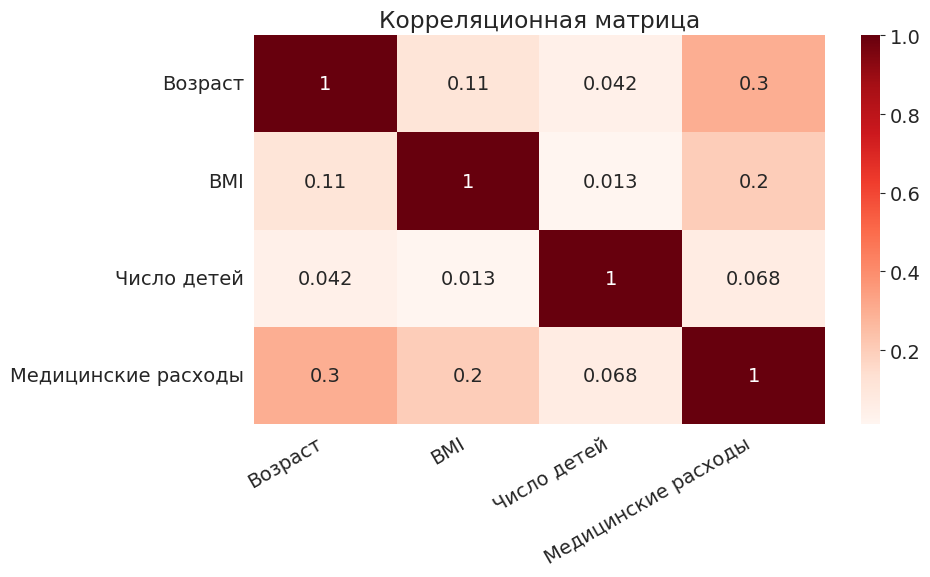

In [182]:
sns.heatmap(medical_df.corr(numeric_only=True), cmap='Reds', annot=True)
plt.title('Корреляционная матрица');
plt.xticks(plt.xticks()[0], ['Возраст', 'BMI', 'Число детей', 'Медицинские расходы'], rotation=30, ha='right')
plt.yticks(plt.yticks()[0], ['Возраст', 'BMI', 'Число детей', 'Медицинские расходы'], rotation=0)
plt.tight_layout();

**Ошибка смешения корреляции и причинности:** высокая корреляция не позволяет делать вывод о причинно-следственной связи между признаками. Два признака $X$ и $Y$ могут коррелировать, если $X$ вызывает $Y$, если $Y$ вызывает $X$ или если оба независимо определяются третьим фактором $Z$. Если одна из причинно-следственных связей нарушится, корреляция может исчезнуть. Возможно и то, что $X$ и $Y$ лишь кажутся связанными из-за слишком маленькой выборки.

Хотя это может казаться очевидным, компьютеры не умеют отличать корреляцию от причинности. При этом решения автоматизированных систем могут иметь серьёзные последствия для общества, поэтому важно исследовать, почему система приходит к конкретному результату. Для установления причинно-следственных связей необходимо человеческое понимание.

Сохраним работу, прежде чем продолжить.

## Линейная регрессия с одним признаком

Теперь мы знаем, что столбцы «smoker» и «age» сильнее всего коррелируют с «charges». Попробуем найти способ оценивать «charges» по «age» для некурящих клиентов. Сначала создадим DataFrame, содержащий только данные некурящих.

In [183]:
non_smoker_df = medical_df[medical_df.smoker == 'no']

Теперь визуализируем зависимость между «age» и «charges».

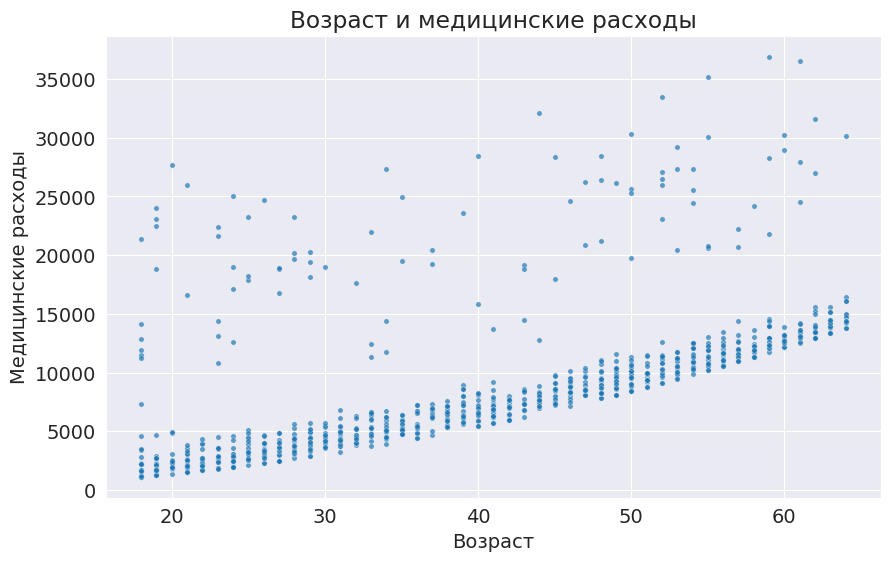

In [184]:
plt.title('Возраст и медицинские расходы')
sns.scatterplot(data=non_smoker_df, x='age', y='charges', alpha=0.7, s=15);
plt.xlabel('Возраст')
plt.ylabel('Медицинские расходы');

За некоторыми исключениями точки, по-видимому, располагаются вдоль прямой. Попробуем подобрать прямую по этим точкам и использовать её для прогноза расходов при заданном возрасте. Прямая в координатах X и Y описывается формулой:

$y = wx + b$

Её определяют два числа: $w$ — «угловой коэффициент», и $b$ — «свободный член».

### Модель

В нашем случае по оси X отложен «age», а по оси Y — «charges». Поэтому мы предполагаем следующую зависимость:

$charges = w \times age + b$

Попробуем определить $w$ и $b$ для прямой, которая лучше всего соответствует данным.

* Этот метод называется _линейной регрессией_, а приведённое уравнение — _моделью линейной регрессии_, поскольку оно описывает зависимость между «age» и «charges» с помощью прямой.

* Числа $w$ и $b$ называются _параметрами_ или _весами_ модели.

* Значения столбца «age» в наборе данных называются _входными данными_ модели, а значения столбца «charges» — значениями _целевой переменной_.

Определим вспомогательную функцию `estimate_charges`, которая вычисляет $charges$ по заданным $age$, $w$ и $b$.

In [185]:
def estimate_charges(age, w, b):
    return w * age + b

Функция `estimate_charges` — наша первая _модель_.

Попробуем _угадать_ значения $w$ и $b$ и с их помощью оценить медицинские расходы.

In [186]:
w = 50
b = 100

In [187]:
ages = non_smoker_df.age
estimated_charges = estimate_charges(ages, w, b)

Оценённые расходы можно изобразить с помощью линейного графика.

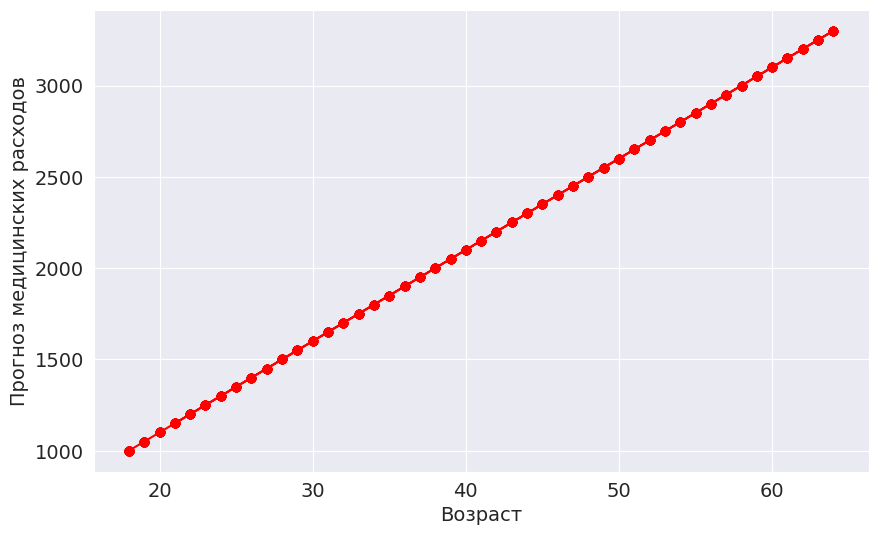

In [188]:
plt.plot(ages, estimated_charges, 'r-o');
plt.xlabel('Возраст');
plt.ylabel('Прогноз медицинских расходов');

Как и ожидалось, точки лежат на прямой.

Наложим эту прямую на фактические данные, чтобы увидеть, насколько хорошо наша _модель_ соответствует _данным_.

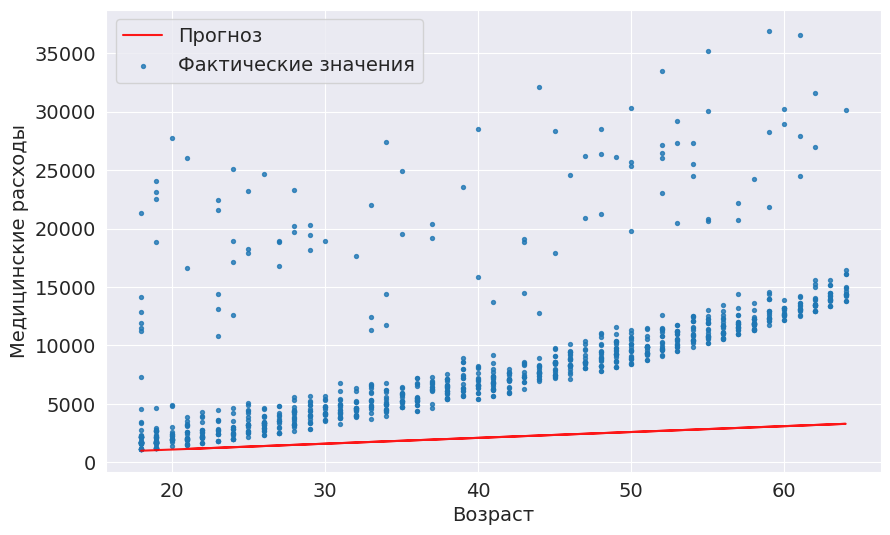

In [189]:
target = non_smoker_df.charges

plt.plot(ages, estimated_charges, 'r', alpha=0.9);
plt.scatter(ages, target, s=8,alpha=0.8);
plt.xlabel('Возраст');
plt.ylabel('Медицинские расходы')
plt.legend(['Прогноз', 'Фактические значения']);

Очевидно, что наши оценки довольно неточны и прямая плохо соответствует данным. Однако можно попробовать разные значения $w$ и $b$, чтобы изменить её положение. Определим вспомогательную функцию `try_parameters`, которая принимает `w` и `b` и строит показанный выше график.

In [190]:
def try_parameters(w, b):
    ages = non_smoker_df.age
    target = non_smoker_df.charges
    
    estimated_charges = estimate_charges(ages, w, b)
    
    plt.plot(ages, estimated_charges, 'r', alpha=0.9);
    plt.scatter(ages, target, s=8,alpha=0.8);
    plt.xlabel('Возраст');
    plt.ylabel('Медицинские расходы')
    plt.legend(['Прогноз', 'Фактические значения']);

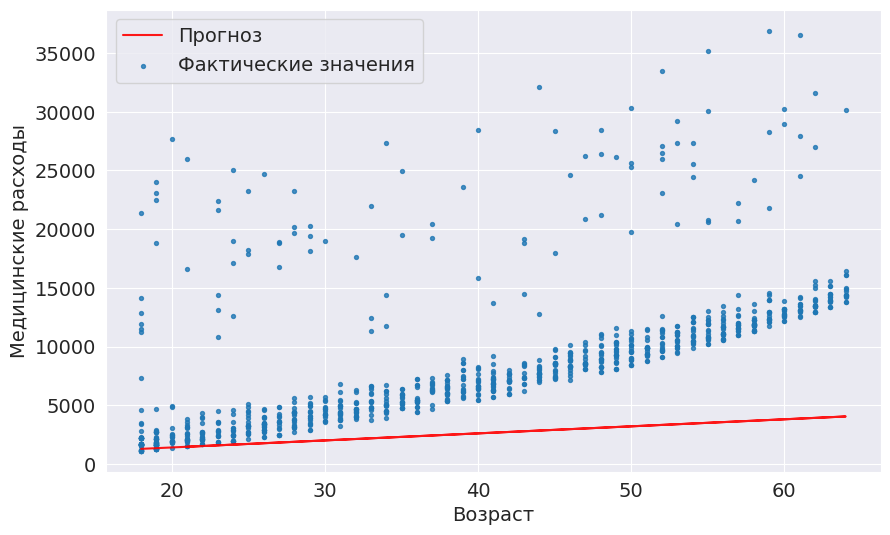

In [191]:
try_parameters(60, 200)

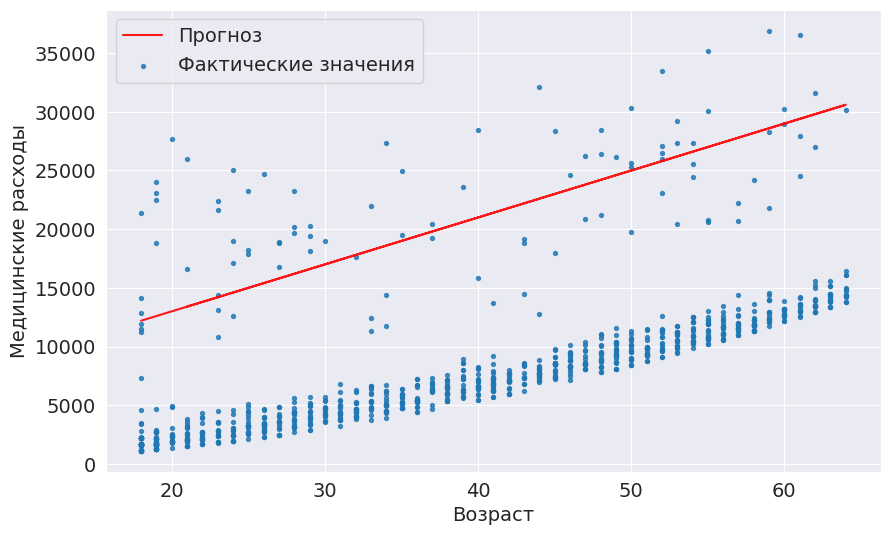

In [192]:
try_parameters(400, 5000)

> **ЗАДАНИЕ**: попробуйте разные значения $w$ и $b$, чтобы найти прямую, которая лучше всего соответствует данным. Как влияет изменение $w$? Как влияет изменение $b$?

Вручную изменяя $w$ и $b$ и стараясь приблизить прямую к точкам, мы _изучаем_ приближённую зависимость между «age» и «charges».

Было бы удобно, если бы компьютер мог сам перебрать разные значения `w` и `b` и _изучить_ зависимость между «age» и «charges». Для этого нужно решить две задачи:

1. Найти способ численно измерить, насколько хорошо прямая соответствует точкам.

2. Вычислив эту «меру соответствия», найти способ изменять `w` и `b` так, чтобы улучшать соответствие.

Если решить эти задачи, компьютер сможет определить `w` и `b` для наилучшей прямой, начав со случайного предположения.

### Функция потерь

Прогнозы модели можно сравнить с фактическими значениями целевой переменной следующим образом:

* Вычислить разность между фактическими значениями и прогнозами. Эта разность называется «остатком».
* Возвести все элементы матрицы разностей в квадрат, чтобы избавиться от отрицательных значений.
* Вычислить среднее значение элементов полученной матрицы.
* Извлечь квадратный корень из результата.

Получится одно число — **корень из среднеквадратичной ошибки** (RMSE). Описанное вычисление можно записать математически:

<img src="https://i.imgur.com/WCanPkA.png" width="360">

Геометрически остатки можно представить следующим образом:

<img src="https://i.imgur.com/ll3NL80.png" width="420">

Определим функцию для вычисления RMSE.

In [193]:
import numpy as np

In [194]:
def rmse(targets, predictions):
    return np.sqrt(np.mean(np.square(targets - predictions)))

Вычислим RMSE нашей модели для пробного набора весов.

In [195]:
w = 50
b = 100

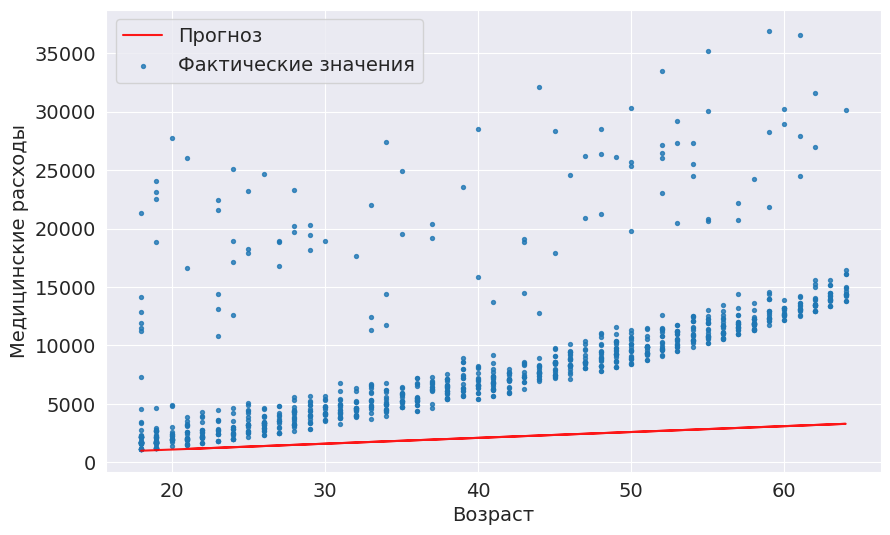

In [196]:
try_parameters(w, b)

In [197]:
targets = non_smoker_df['charges']
predicted = estimate_charges(non_smoker_df.age, w, b)

In [198]:
rmse(targets, predicted)

np.float64(8461.949562575493)

Полученное число можно интерпретировать так: *в среднем каждый прогноз отличается от фактического значения целевой переменной на \\$8461*.

Этот результат называется *потерями*, поскольку показывает, насколько плохо модель прогнозирует целевую переменную. Он отражает потерю информации в модели: чем меньше потери, тем лучше модель.

Изменим функцию `try_parameters`, чтобы она также показывала значение функции потерь.

In [199]:
def try_parameters(w, b):
    ages = non_smoker_df.age
    target = non_smoker_df.charges
    predictions = estimate_charges(ages, w, b)
    
    plt.plot(ages, predictions, 'r', alpha=0.9);
    plt.scatter(ages, target, s=8,alpha=0.8);
    plt.xlabel('Возраст');
    plt.ylabel('Медицинские расходы')
    plt.legend(['Прогноз', 'Фактические значения']);
    
    loss = rmse(target, predictions)
    print("Значение функции потерь RMSE: ", loss)

Значение функции потерь RMSE:  8461.949562575493


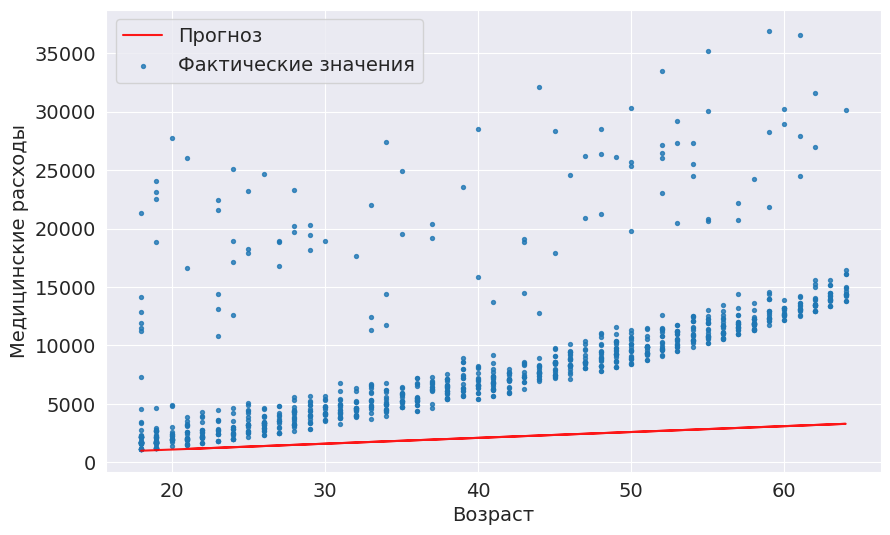

In [200]:
try_parameters(50, 100)

> **ЗАДАНИЕ**: попробуйте разные значения $w$ и $b$, чтобы минимизировать функцию потерь RMSE. Какого минимального значения вам удалось достичь? Можете ли вы предложить общую стратегию поиска лучших значений $w$ и $b$ методом проб и ошибок?

### Оптимизатор

Теперь нужна стратегия изменения весов `w` и `b`, которая будет уменьшать потери и улучшать соответствие прямой данным.

* Метод наименьших квадратов: https://www.youtube.com/watch?v=szXbuO3bVRk (лучше подходит для небольших наборов данных)
* Стохастический градиентный спуск: https://www.youtube.com/watch?v=sDv4f4s2SB8 (лучше подходит для больших наборов данных)

Оба метода преследуют одну цель — минимизировать потери. Однако метод наименьших квадратов непосредственно вычисляет лучшие значения `w` и `b` с помощью матричных операций, а градиентный спуск использует итерационный подход: начинает со случайных значений `w` и `b` и постепенно улучшает их с помощью производных.

Вот визуализация работы градиентного спуска:

![](https://miro.medium.com/max/1728/1*NO-YvpHHadk5lLxtg4Gfrw.gif)

Разве это не похоже на нашу стратегию постепенного приближения прямой к точкам?

### Линейная регрессия с помощью Scikit-learn

На практике вам не потребуется самостоятельно реализовывать ни один из этих методов. Можно воспользоваться библиотекой, например `scikit-learn`, которая сделает это за вас.

Используем класс `LinearRegression` из `scikit-learn`, чтобы методом наименьших квадратов найти прямую, наилучшим образом описывающую зависимость «charges» от «age».

In [201]:
from sklearn.linear_model import LinearRegression

Сначала создадим новый объект модели.

In [202]:
model = LinearRegression()

Затем с помощью метода `fit` найдём прямую, которая лучше всего соответствует входным данным и значениям целевой переменной.

In [203]:
help(model.fit)

Help on method fit in module sklearn.linear_model._base:

fit(X, y, sample_weight=None) method of sklearn.linear_model._base.LinearRegression instance
    Fit linear model.

    Parameters
    ----------
    X : {array-like, sparse matrix} of shape (n_samples, n_features)
        Training data.

    y : array-like of shape (n_samples,) or (n_samples, n_targets)
        Target values. Will be cast to X's dtype if necessary.

    sample_weight : array-like of shape (n_samples,), default=None
        Individual weights for each sample.

        .. versionadded:: 0.17
           parameter *sample_weight* support to LinearRegression.

    Returns
    -------
    self : object
        Fitted Estimator.



Обратите внимание: входные данные `X` должны быть двумерным массивом, поэтому нужно передать DataFrame, а не отдельный столбец Series.

In [204]:
inputs = non_smoker_df[['age']]
targets = non_smoker_df.charges
print('Размер входных данных:', inputs.shape)
print('Размер целевой переменной:', targets.shape)

Размер входных данных: (1064, 1)
Размер целевой переменной: (1064,)


Обучим модель на данных.

In [205]:
model.fit(inputs, targets)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


Теперь можно получать прогнозы модели. Попробуем спрогнозировать расходы для клиентов в возрасте 23, 37 и 61 года.

In [206]:
model.predict(np.array([[23], 
                        [37], 
                        [61]]))

c:\Users\Денис\Documents\Программирование\Portfolio\Medical Insurance Cost Prediction\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning:

X does not have valid feature names, but LinearRegression was fitted with feature names



array([ 4055.30443855,  7796.78921819, 14210.76312614])

Выглядят ли эти значения правдоподобно? Сравните их с диаграммой рассеяния выше.

Вычислим прогнозы для всего набора входных данных.

In [207]:
predictions = model.predict(inputs)

In [208]:
predictions

array([2719.0598744 , 5391.54900271, 6727.79356686, ..., 2719.0598744 ,
       2719.0598744 , 3520.80661289], shape=(1064,))

Вычислим функцию потерь RMSE, чтобы оценить качество модели.

In [209]:
rmse(targets, predictions)

np.float64(4662.505766636395)

По-видимому, наш прогноз в среднем ошибается на $4000, что не так уж плохо, учитывая наличие нескольких выбросов.

Параметры модели хранятся в атрибутах `coef_` и `intercept_`.

In [210]:
# w
model.coef_

array([267.24891283])

In [211]:
# b
model.intercept_

np.float64(-2091.4205565650864)

Близки ли эти параметры к вашим лучшим предположениям?

Визуализируем прямую, заданную полученными параметрами.

Значение функции потерь RMSE:  4662.505766636395


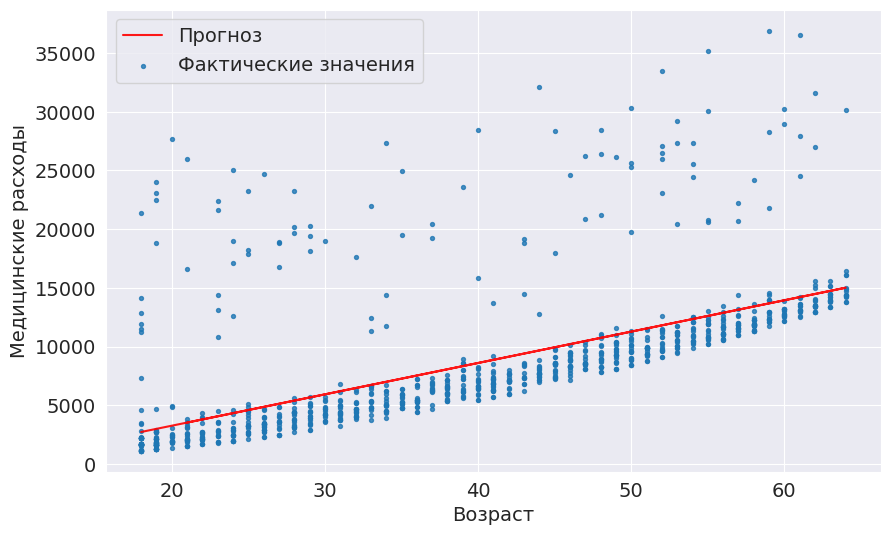

In [212]:
try_parameters(model.coef_, model.intercept_)

Прямая действительно проходит достаточно близко к точкам. Она находится немного выше основного скопления, поскольку модель старается учесть и выбросы.

> **ЗАДАНИЕ**: используйте класс [`SGDRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html) из `scikit-learn`, чтобы обучить модель методом стохастического градиентного спуска. Получите прогнозы и вычислите значение функции потерь. Отличается ли результат?

> **ЗАДАНИЕ**: повторите действия из этого раздела, чтобы обучить модель линейной регрессии для оценки медицинских расходов курящих клиентов. Визуализируйте фактические значения целевой переменной и прогнозы, затем вычислите значение функции потерь.

### Машинное обучение

Поздравляем, вы только что обучили свою первую _модель машинного обучения!_ Машинное обучение — это процесс вычисления наилучших параметров модели, описывающей зависимость между признаками и целевой переменной.

В каждой задаче машинного обучения есть три составляющие:

1. **Модель**

2. **Функция потерь**

3. **Оптимизатор**

В следующих уроках мы рассмотрим несколько примеров каждой из этих составляющих. Их взаимосвязь можно представить следующим образом:

<img src="https://www.deepnetts.com/blog/wp-content/uploads/2019/02/SupervisedLearning.png" width="480">

Как мы увидели, для обучения модели машинного обучения с помощью `scikit-learn` достаточно всего нескольких строк кода.

In [213]:
# Подготовка входных данных и целевой переменной
inputs, targets = non_smoker_df[['age']], non_smoker_df['charges']

# Создание и обучение модели
model = LinearRegression().fit(inputs, targets)

# Получение прогнозов
predictions = model.predict(inputs)

# Вычисление функции потерь для оценки качества модели
loss = rmse(targets, predictions)
print('Значение функции потерь:', loss)

Значение функции потерь: 4662.505766636395


Сохраним работу, прежде чем продолжить.

## Линейная регрессия с несколькими признаками

До сих пор для оценки «charges» мы использовали только признак «age». Добавить другой признак, например «bmi», довольно просто. Предположим следующую зависимость:

$charges = w_1 \times age + w_2 \times bmi + b$

Чтобы включить BMI в модель, достаточно изменить одну строку кода.

In [214]:
# Подготовка входных данных и целевой переменной
inputs, targets = non_smoker_df[['age', 'bmi']], non_smoker_df['charges']

# Создание и обучение модели
model = LinearRegression().fit(inputs, targets)

# Получение прогнозов
predictions = model.predict(inputs)

# Вычисление функции потерь для оценки качества модели
loss = rmse(targets, predictions)
print('Значение функции потерь:', loss)

Значение функции потерь: 4662.3128354612945


Как видите, добавление BMI почти не снижает потери: BMI очень слабо коррелирует с медицинскими расходами, особенно у некурящих.

In [215]:
non_smoker_df.charges.corr(non_smoker_df.bmi)

np.float64(0.08403654312833271)

In [216]:
fig = px.scatter(non_smoker_df, labels=plot_labels, x='bmi', y='charges', title='BMI и медицинские расходы')
fig.update_traces(marker_size=5)
fig.update_layout(font_family='Arial')
fig.show(config=plotly_config)

Связь между всеми тремя переменными — «age», «bmi» и «charges» — также можно показать на трёхмерной диаграмме рассеяния.

In [217]:
fig = px.scatter_3d(non_smoker_df, labels=plot_labels, x='age', y='bmi', z='charges')
fig.update_traces(marker_size=3, marker_opacity=0.5)
fig.update_layout(font_family='Arial')
fig.show(config=plotly_config)

Видно, что трёхмерную диаграмму рассеяния интерпретировать сложнее, чем двумерную. По мере добавления признаков визуализировать их все одновременно становится невозможно, поэтому мы используем такие численные характеристики, как корреляция и значение функции потерь.

Также проверим параметры модели.

In [218]:
model.coef_, model.intercept_

(array([266.87657817,   7.07547666]), np.float64(-2293.6320906488727))

Очевидно, что вес BMI значительно меньше, и причина понятна. Его вклад невелик, и даже этот вклад, вероятно, случаен. Важно помнить: невозможно обнаружить зависимость, которой нет, какой бы метод машинного обучения или алгоритм оптимизации вы ни использовали.

> **ЗАДАНИЕ**: обучите модель линейной регрессии для оценки расходов только по BMI. Как вы думаете, будет ли она лучше или хуже ранее обученных моделей?

Пойдём дальше и добавим последний числовой столбец — «children», который, по-видимому, в некоторой степени коррелирует с «charges».

$charges = w_1 \times age + w_2 \times bmi + w_3 \times charges + b$

In [219]:
non_smoker_df.charges.corr(non_smoker_df.children)

np.float64(0.13892870453542205)

In [220]:
fig = px.strip(non_smoker_df, labels=plot_labels, x='children', y='charges', title= "Число детей и медицинские расходы")
fig.update_traces(marker_size=4, marker_opacity=0.7)
fig.update_layout(font_family='Arial')
fig.show(config=plotly_config)

In [221]:
# Подготовка входных данных и целевой переменной
inputs, targets = non_smoker_df[['age', 'bmi', 'children']], non_smoker_df['charges']

# Создание и обучение модели
model = LinearRegression().fit(inputs, targets)

# Получение прогнозов
predictions = model.predict(inputs)

# Вычисление функции потерь для оценки качества модели
loss = rmse(targets, predictions)
print('Значение функции потерь:', loss)

Значение функции потерь: 4608.470405038246


Снова заметного снижения потерь не наблюдается, хотя оно и больше, чем при добавлении BMI.

> **ЗАДАНИЕ**: повторите действия из этого раздела, чтобы обучить модель линейной регрессии для оценки медицинских расходов курящих клиентов. Визуализируйте фактические значения целевой переменной и прогнозы, затем вычислите значение функции потерь.

> **ЗАДАНИЕ**: повторите действия из этого раздела, чтобы обучить модель линейной регрессии для оценки медицинских расходов всех клиентов. Визуализируйте фактические значения целевой переменной и прогнозы, затем вычислите значение функции потерь. Стали потери ниже или выше?

In [222]:
# Подготовка входных данных и целевой переменной
inputs, targets = medical_df[['age', 'bmi', 'children']], medical_df['charges']

# Создание и обучение модели
model = LinearRegression().fit(inputs, targets)

# Получение прогнозов
predictions = model.predict(inputs)

# Вычисление функции потерь для оценки качества модели
loss = rmse(targets, predictions)
print('Значение функции потерь:', loss)

Значение функции потерь: 11355.317901125973


Сохраним работу, прежде чем продолжить.

## Использование категориальных признаков в машинном обучении

До сих пор мы использовали только числовые столбцы, поскольку вычисления можно выполнять только с числами. Если использовать и категориальные столбцы, например «smoker», можно обучить единую модель для всего набора данных.

Чтобы использовать категориальные столбцы, достаточно преобразовать их в числа. Для этого есть три распространённых способа:

1. Если столбец содержит только две категории (такой признак называют бинарным), их значения можно заменить на 0 и 1.
2. Если категорий больше двух, можно применить унитарное кодирование (one-hot encoding): создать для каждой категории отдельный столбец со значениями 0 и 1.
3. Если категории имеют естественный порядок (например, холодно, нейтрально, тепло, жарко), их можно преобразовать в числа (например, 1, 2, 3, 4), сохранив этот порядок. Такие признаки называют порядковыми.

## Бинарные категории

Столбец «smoker» содержит только два значения: «yes» и «no». Создадим новый столбец «smoker_code», в котором «no» будет соответствовать 0, а «yes» — 1.

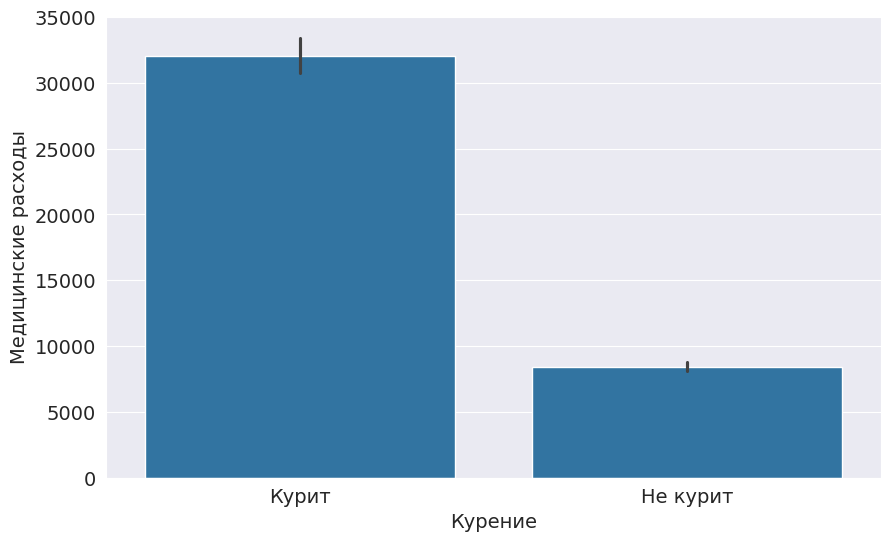

In [223]:
sns.barplot(data=medical_df, x='smoker', y='charges');
plt.xlabel('Курение')
plt.ylabel('Медицинские расходы')
plt.xticks([0, 1], ['Курит', 'Не курит']);

In [224]:
smoker_codes = {'no': 0, 'yes': 1}
medical_df['smoker_code'] = medical_df.smoker.map(smoker_codes)

In [225]:
medical_df.charges.corr(medical_df.smoker_code)

np.float64(0.7872514304984778)

In [226]:
medical_df

,age,sex,bmi,children,smoker,region,charges,smoker_code
0,19,female,27.900,0,yes,southwest,16884.92400,1
1,18,male,33.770,1,no,southeast,1725.55230,0
2,28,male,33.000,3,no,southeast,4449.46200,0
3,33,male,22.705,0,no,northwest,21984.47061,0
4,32,male,28.880,0,no,northwest,3866.85520,0
...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,0
1334,18,female,31.920,0,no,northeast,2205.98080,0
1335,18,female,36.850,0,no,southeast,1629.83350,0
1336,21,female,25.800,0,no,southwest,2007.94500,0


Теперь столбец `smoker_df` можно использовать в линейной регрессии.

$charges = w_1 \times age + w_2 \times bmi + w_3 \times charges + w_4 \times smoker + b$

In [227]:
# Подготовка входных данных и целевой переменной
inputs, targets = medical_df[['age', 'bmi', 'children', 'smoker_code']], medical_df['charges']

# Создание и обучение модели
model = LinearRegression().fit(inputs, targets)

# Получение прогнозов
predictions = model.predict(inputs)

# Вычисление функции потерь для оценки качества модели
loss = rmse(targets, predictions)
print('Значение функции потерь:', loss)

Значение функции потерь: 6056.439217188081


Потери снизились с `11355` до `6056` — почти на 50%! Важный вывод: никогда не игнорируйте категориальные данные.

Попробуем также добавить столбец «sex».

$charges = w_1 \times age + w_2 \times bmi + w_3 \times charges + w_4 \times smoker + w_5 \times sex + b$

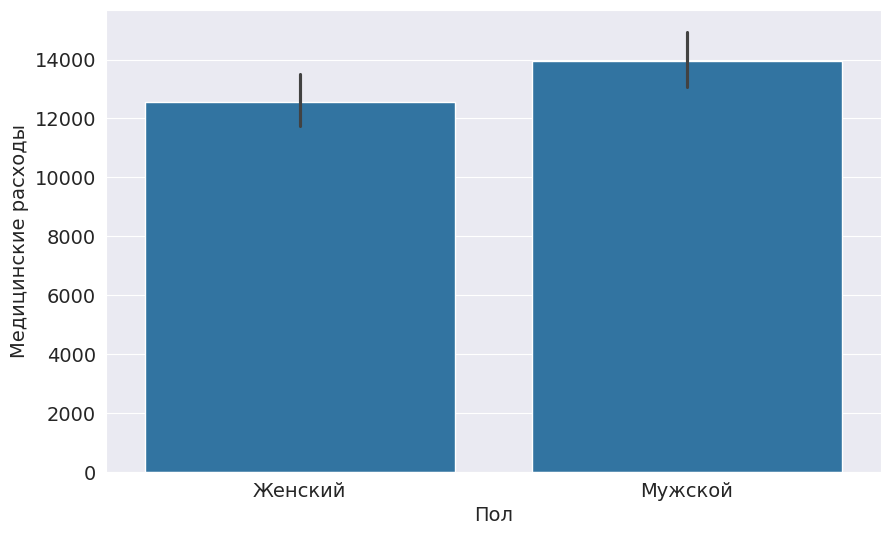

In [228]:
sns.barplot(data=medical_df, x='sex', y='charges')
plt.xlabel('Пол')
plt.ylabel('Медицинские расходы')
plt.xticks([0, 1], ['Женский', 'Мужской']);

In [229]:
sex_codes = {'female': 0, 'male': 1}

In [230]:
medical_df['sex_code'] = medical_df.sex.map(sex_codes)

In [231]:
medical_df.charges.corr(medical_df.sex_code)

np.float64(0.05729206220202533)

In [ ]:
# Подготовка входных данных и целевой переменной
inputs, targets = medical_df[['age', 'bmi', 'children', 'smoker_code', 'sex_code']], medical_df['charges']

# Создание и обучение модели
model = LinearRegression().fit(inputs, targets)

# Получение прогнозов
predictions = model.predict(inputs)

# Вычисление функции потерь для оценки качества модели
loss = rmse(targets, predictions)
print('Значение функции потерь:', loss)

Значение функции потерь: 6056.100708754546


Как и можно было ожидать, это заметно влияет на значение функции потерь.

### Унитарное кодирование

Столбец «region» содержит четыре значения, поэтому потребуется унитарное кодирование: создадим отдельный столбец для каждого региона.

![](https://i.imgur.com/n8GuiOO.png)

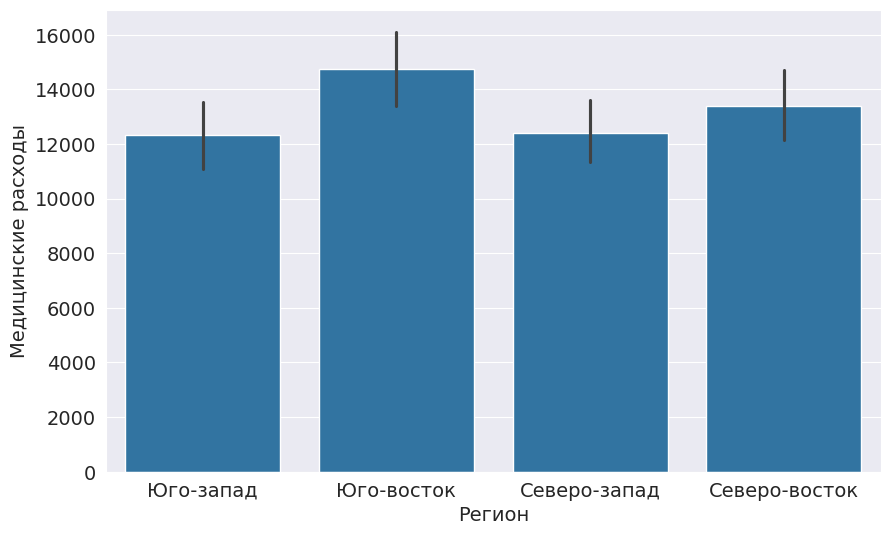

In [233]:
sns.barplot(data=medical_df, x='region', y='charges');
plt.xlabel('Регион')
plt.ylabel('Медицинские расходы')
plt.xticks([0, 1, 2, 3], ['Юго-запад', 'Юго-восток', 'Северо-запад', 'Северо-восток']);

In [234]:
from sklearn import preprocessing
enc = preprocessing.OneHotEncoder()
enc.fit(medical_df[['region']])
enc.categories_

[array(['northeast', 'northwest', 'southeast', 'southwest'], dtype=object)]

In [235]:
one_hot = enc.transform(medical_df[['region']]).toarray()
one_hot

array([[0., 0., 0., 1.],
       [0., 0., 1., 0.],
       [0., 0., 1., 0.],
       ...,
       [0., 0., 1., 0.],
       [0., 0., 0., 1.],
       [0., 1., 0., 0.]], shape=(1338, 4))

In [236]:
medical_df[['northeast', 'northwest', 'southeast', 'southwest']] = one_hot

In [237]:
medical_df

,age,sex,bmi,children,smoker,region,charges,smoker_code,sex_code,northeast,northwest,southeast,southwest
0,19,female,27.900,0,yes,southwest,16884.92400,1,0,0.0,0.0,0.0,1.0
1,18,male,33.770,1,no,southeast,1725.55230,0,1,0.0,0.0,1.0,0.0
2,28,male,33.000,3,no,southeast,4449.46200,0,1,0.0,0.0,1.0,0.0
3,33,male,22.705,0,no,northwest,21984.47061,0,1,0.0,1.0,0.0,0.0
4,32,male,28.880,0,no,northwest,3866.85520,0,1,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,0,1,0.0,1.0,0.0,0.0
1334,18,female,31.920,0,no,northeast,2205.98080,0,0,1.0,0.0,0.0,0.0
1335,18,female,36.850,0,no,southeast,1629.83350,0,0,0.0,0.0,1.0,0.0
1336,21,female,25.800,0,no,southwest,2007.94500,0,0,0.0,0.0,0.0,1.0


Включим столбцы регионов в модель линейной регрессии.

$charges = w_1 \times age + w_2 \times bmi + w_3 \times charges + w_4 \times smoker + w_5 \times sex + w_6 \times region + b$

In [238]:
# Подготовка входных данных и целевой переменной
input_cols = ['age', 'bmi', 'children', 'smoker_code', 'sex_code', 'northeast', 'northwest', 'southeast', 'southwest']
inputs, targets = medical_df[input_cols], medical_df['charges']

# Создание и обучение модели
model = LinearRegression().fit(inputs, targets)

# Получение прогнозов
predictions = model.predict(inputs)

# Вычисление функции потерь для оценки качества модели
loss = rmse(targets, predictions)
print('Значение функции потерь:', loss)

Значение функции потерь: 6041.6796511744515


И снова это приводит лишь к небольшому снижению потерь.

> **ЗАДАНИЕ**: будут ли две отдельные модели линейной регрессии — для курящих и некурящих — лучше одной общей модели? Почему? Проверьте это на практике и попробуйте обосновать ответ данными.

Сохраним работу, прежде чем продолжить.

## Улучшение модели

Обсудим и применим ещё несколько способов улучшить нашу модель.

### Масштабирование признаков

Напомним, что требования регулирующих органов обязывают нас также объяснять, чем обусловлены прогнозы модели.

$charges = w_1 \times age + w_2 \times bmi + w_3 \times charges + w_4 \times smoker + w_5 \times sex + w_6 \times region + b$

Чтобы сравнить важность признаков, в первую очередь может возникнуть желание сравнить их веса.

In [239]:
model.coef_

array([  256.85635254,   339.19345361,   475.50054515, 23848.53454191,
        -131.3143594 ,   587.00923503,   234.0453356 ,  -448.01281436,
        -373.04175627])

In [240]:
model.intercept_

np.float64(-12525.54781119545)

In [241]:
weights_df = pd.DataFrame({
    'feature': np.append(input_cols, 1),
    'weight': np.append(model.coef_, model.intercept_)
})
weights_df

,feature,weight
0,age,256.856353
1,bmi,339.193454
2,children,475.500545
3,smoker_code,23848.534542
4,sex_code,-131.314359
5,northeast,587.009235
6,northwest,234.045336
7,southeast,-448.012814
8,southwest,-373.041756
9,1,-12525.547811


Хотя веса BMI и «northeast» кажутся выше веса возраста, нужно учитывать, что диапазон значений BMI ограничен (от 15 до 40), а столбец «northeast» принимает только значения 0 и 1.

Различия в диапазонах значений столбцов приводят к двум проблемам:

1. Нельзя напрямую сравнить веса разных столбцов и определить, какие признаки важнее.
2. Столбец с более широким диапазоном значений может непропорционально сильно влиять на потери и доминировать в процессе оптимизации.

Поэтому числовые признаки часто масштабируют, в частности стандартизируют: вычитают среднее и делят на стандартное отклонение.

![](https://i.imgur.com/dT5fLFI.png)

Для масштабирования можно использовать класс StandardScaler из `scikit-learn`.

In [242]:
medical_df

,age,sex,bmi,children,smoker,region,charges,smoker_code,sex_code,northeast,northwest,southeast,southwest
0,19,female,27.900,0,yes,southwest,16884.92400,1,0,0.0,0.0,0.0,1.0
1,18,male,33.770,1,no,southeast,1725.55230,0,1,0.0,0.0,1.0,0.0
2,28,male,33.000,3,no,southeast,4449.46200,0,1,0.0,0.0,1.0,0.0
3,33,male,22.705,0,no,northwest,21984.47061,0,1,0.0,1.0,0.0,0.0
4,32,male,28.880,0,no,northwest,3866.85520,0,1,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,0,1,0.0,1.0,0.0,0.0
1334,18,female,31.920,0,no,northeast,2205.98080,0,0,1.0,0.0,0.0,0.0
1335,18,female,36.850,0,no,southeast,1629.83350,0,0,0.0,0.0,1.0,0.0
1336,21,female,25.800,0,no,southwest,2007.94500,0,0,0.0,0.0,0.0,1.0


In [243]:
from sklearn.preprocessing import StandardScaler

In [244]:
numeric_cols = ['age', 'bmi', 'children'] 
scaler = StandardScaler()
scaler.fit(medical_df[numeric_cols])

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [245]:
scaler.mean_

array([39.20702541, 30.66339686,  1.09491779])

In [246]:
scaler.var_

array([197.25385199,  37.16008997,   1.45212664])

Теперь масштабируем данные следующим образом:

In [247]:
scaled_inputs = scaler.transform(medical_df[numeric_cols])
scaled_inputs

array([[-1.43876426, -0.45332   , -0.90861367],
       [-1.50996545,  0.5096211 , -0.07876719],
       [-0.79795355,  0.38330685,  1.58092576],
       ...,
       [-1.50996545,  1.0148781 , -0.90861367],
       [-1.29636188, -0.79781341, -0.90861367],
       [ 1.55168573, -0.26138796, -0.90861367]], shape=(1338, 3))

Полученные значения можно объединить с категориальными данными.

In [248]:
cat_cols = ['smoker_code', 'sex_code', 'northeast', 'northwest', 'southeast', 'southwest']
categorical_data = medical_df[cat_cols].values

In [249]:
inputs = np.concatenate((scaled_inputs, categorical_data), axis=1)
targets = medical_df.charges

# Создание и обучение модели
model = LinearRegression().fit(inputs, targets)

# Получение прогнозов
predictions = model.predict(inputs)

# Вычисление функции потерь для оценки качества модели
loss = rmse(targets, predictions)
print('Значение функции потерь:', loss)

Значение функции потерь: 6041.679651174452


Теперь можно сравнить веса в формуле:

$charges = w_1 \times age + w_2 \times bmi + w_3 \times charges + w_4 \times smoker + w_5 \times sex + w_6 \times region + b$

In [250]:
weights_df = pd.DataFrame({
    'feature': np.append(numeric_cols + cat_cols, 1),
    'weight': np.append(model.coef_, model.intercept_)
})
weights_df.sort_values('weight', ascending=False)

,feature,weight
3,smoker_code,23848.534542
9,1,8466.483215
0,age,3607.472736
1,bmi,2067.691966
5,northeast,587.009235
2,children,572.998210
6,northwest,234.045336
4,sex_code,-131.314359
8,southwest,-373.041756
7,southeast,-448.012814


Как теперь видно, наиболее важные признаки:

1. Курение
2. Возраст
3. BMI

### Создание тестовой выборки

Модели, подобные созданной в этом уроке, предназначены для практического применения. Обычно небольшую часть данных (например, 10%) откладывают исключительно для тестирования и представления результатов работы модели.

In [251]:
from sklearn.model_selection import train_test_split

In [252]:
inputs_train, inputs_test, targets_train, targets_test = train_test_split(inputs, targets, test_size=0.1)

In [253]:
# Создание и обучение модели
model = LinearRegression().fit(inputs_train, targets_train)

# Получение прогнозов
predictions_test = model.predict(inputs_test)

# Вычисление функции потерь для оценки качества модели
loss = rmse(targets_test, predictions_test)
print('Потери на тестовой выборке:', loss)

Потери на тестовой выборке: 5759.870023848627


Сравним это значение с потерями на обучающей выборке.

In [254]:
# Получение прогнозов
predictions_train = model.predict(inputs_train)

# Вычисление функции потерь для оценки качества модели
loss = rmse(targets_train, predictions_train)
print('Потери на обучающей выборке:', loss)

Потери на обучающей выборке: 6075.495925319785


Можете ли вы объяснить, почему потери на обучающей выборке ниже, чем на тестовой? В следующих уроках мы разберём это гораздо подробнее.

### Как подойти к задаче машинного обучения

Для решения задачи машинного обучения можно использовать следующую стратегию:

1. Исследовать данные и найти корреляции между входными признаками и целевой переменной.
2. Выбрать подходящие модель, функцию потерь и оптимизатор.
3. Масштабировать числовые признаки и выполнить унитарное кодирование категориальных данных.
4. Выделить часть данных в тестовую выборку.
5. Обучить модель.
6. Получить прогнозы на тестовой выборке и вычислить значение функции потерь.

В следующих уроках мы применим этот подход к нескольким задачам.

Сохраним работу, прежде чем продолжить.

## Итоги и дополнительные материалы

Мы рассмотрели следующие темы:

- Типичная постановка задачи машинного обучения
- Загрузка и исследование набора данных для машинного обучения
- Линейная регрессия с одной переменной с помощью Scikit-learn
- Линейная регрессия с несколькими переменными
- Использование категориальных признаков в машинном обучении
- Коэффициенты регрессии и важность признаков
- Создание обучающей и тестовой выборок для представления результатов

Примените изученные методы к следующим наборам данных:

- https://www.kaggle.com/vikrishnan/boston-house-prices
- https://www.kaggle.com/sohier/calcofi
- https://www.kaggle.com/budincsevity/szeged-weather

Подробнее о линейной регрессии можно узнать по ссылкам:

- https://jovian.ai/aakashns/02-linear-regression
- https://www.kaggle.com/hely333/eda-regression
- https://www.youtube.com/watch?v=kHwlB_j7Hkc

## Сравнение моделей и итоговая оценка качества

In [255]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [256]:
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

In [257]:
medical_df = pd.read_csv('medical.csv')
medical_df.shape

(1338, 7)

In [258]:
medical_df.duplicated().sum()

np.int64(1)

In [259]:
medical_df = medical_df.drop_duplicates()

In [260]:
medical_df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [261]:
numeric_cols = ['age', 'bmi', 'children']
cat_cols = ['smoker', 'sex', 'region']
input_cols = numeric_cols + cat_cols

In [262]:
inputs = medical_df[input_cols]
targets = medical_df.charges

In [ ]:
# Повторяем эксперимент с исходными признаками и предобработкой только на обучающей выборке
inputs_train, inputs_test, targets_train, targets_test = train_test_split(
    inputs, targets, test_size=0.2, random_state=10
)

In [264]:
print('Обучающая выборка:', inputs_train.shape)
print('Тестовая выборка:', inputs_test.shape)

Обучающая выборка: (1069, 6)
Тестовая выборка: (268, 6)


In [265]:
scaler = StandardScaler()
encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)

In [266]:
preprocessor = ColumnTransformer([
    ('numeric', scaler, numeric_cols),
    ('categorical', encoder, cat_cols)
])

In [267]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [268]:
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

In [269]:
results_df = pd.DataFrame(columns=[
    'model', 'train_RMSE', 'cv_MAE', 'cv_RMSE', 'cv_RMSE_std', 'cv_R2'
])

In [270]:
dummy_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('regressor', DummyRegressor(strategy='mean'))
])

In [271]:
dummy_scores = cross_validate(
    dummy_model, inputs_train, targets_train,
    cv=cv, scoring=scoring, return_train_score=True, error_score='raise'
)

In [ ]:
results_df.loc[0] = [
    'DummyRegressor', -dummy_scores['train_RMSE'].mean(),
    -dummy_scores['test_MAE'].mean(), -dummy_scores['test_RMSE'].mean(),
    dummy_scores['test_RMSE'].std(), dummy_scores['test_R2'].mean()
]и
results_df.round(3)

,model,train_RMSE,cv_MAE,cv_RMSE,cv_RMSE_std,cv_R2
0,DummyRegressor,11699.306,8789.317,11688.798,640.878,-0.003


In [273]:
linear_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('regressor', LinearRegression())
])

In [274]:
linear_scores = cross_validate(
    linear_model, inputs_train, targets_train,
    cv=cv, scoring=scoring, return_train_score=True, error_score='raise'
)

In [275]:
results_df.loc[1] = [
    'LinearRegression', -linear_scores['train_RMSE'].mean(),
    -linear_scores['test_MAE'].mean(), -linear_scores['test_RMSE'].mean(),
    linear_scores['test_RMSE'].std(), linear_scores['test_R2'].mean()
]
results_df.round(3)

,model,train_RMSE,cv_MAE,cv_RMSE,cv_RMSE_std,cv_R2
0,DummyRegressor,11699.306,8789.317,11688.798,640.878,-0.003
1,LinearRegression,6075.917,4221.963,6123.651,189.302,0.723


In [276]:
ridge_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('regressor', Ridge())
])

In [277]:
ridge_params = {'regressor__alpha': [0.1, 1, 10, 100]}

In [278]:
ridge_search = GridSearchCV(
    ridge_model, ridge_params, cv=cv, scoring=scoring, refit='RMSE',
    return_train_score=True, error_score='raise'
)
ridge_search.fit(inputs_train, targets_train);

In [279]:
ridge_search.best_params_

{'regressor__alpha': 0.1}

In [280]:
ridge_scores = pd.DataFrame(ridge_search.cv_results_)
ridge_scores = ridge_scores.iloc[ridge_search.best_index_]

In [281]:
results_df.loc[2] = [
    'Ridge', -ridge_scores['mean_train_RMSE'],
    -ridge_scores['mean_test_MAE'], -ridge_scores['mean_test_RMSE'],
    ridge_scores['std_test_RMSE'], ridge_scores['mean_test_R2']
]
results_df.round(3)

,model,train_RMSE,cv_MAE,cv_RMSE,cv_RMSE_std,cv_R2
0,DummyRegressor,11699.306,8789.317,11688.798,640.878,-0.003
1,LinearRegression,6075.917,4221.963,6123.651,189.302,0.723
2,Ridge,6075.921,4222.977,6123.642,189.112,0.723


In [282]:
forest_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('regressor', RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=1))
])

In [283]:
forest_params = {
    'regressor__max_depth': [5, 10, None],
    'regressor__min_samples_leaf': [1, 3, 5]
}

In [284]:
forest_search = GridSearchCV(
    forest_model, forest_params, cv=cv, scoring=scoring, refit='RMSE',
    return_train_score=True, error_score='raise'
)
forest_search.fit(inputs_train, targets_train);

In [285]:
forest_search.best_params_

{'regressor__max_depth': 5, 'regressor__min_samples_leaf': 5}

In [286]:
forest_scores = pd.DataFrame(forest_search.cv_results_)
forest_scores = forest_scores.iloc[forest_search.best_index_]

In [287]:
results_df.loc[3] = [
    'RandomForestRegressor', -forest_scores['mean_train_RMSE'],
    -forest_scores['mean_test_MAE'], -forest_scores['mean_test_RMSE'],
    forest_scores['std_test_RMSE'], forest_scores['mean_test_R2']
]

In [288]:
results_df.sort_values('cv_RMSE').round(3)

,model,train_RMSE,cv_MAE,cv_RMSE,cv_RMSE_std,cv_R2
3,RandomForestRegressor,4108.939,2544.334,4577.397,195.950,0.844
2,Ridge,6075.921,4222.977,6123.642,189.112,0.723
1,LinearRegression,6075.917,4221.963,6123.651,189.302,0.723
0,DummyRegressor,11699.306,8789.317,11688.798,640.878,-0.003


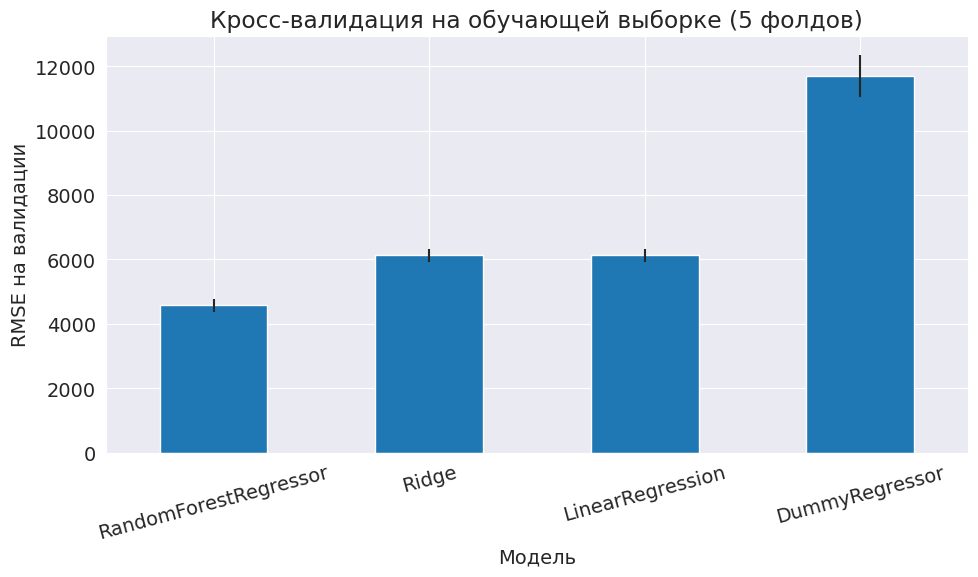

In [289]:
results_df.sort_values('cv_RMSE').plot.bar(
    x='model', y='cv_RMSE', yerr='cv_RMSE_std', legend=False, rot=15
)
plt.ylabel('RMSE на валидации')
plt.title('Кросс-валидация на обучающей выборке (5 фолдов)')
plt.tight_layout();
plt.xlabel('Модель');

In [290]:
best_model = forest_search.best_estimator_
best_model['regressor']

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [291]:
linear_model.fit(inputs_train, targets_train);

In [292]:
weights_df = pd.DataFrame({
    'feature': linear_model['preprocessor'].get_feature_names_out(),
    'weight': linear_model['regressor'].coef_
})
weights_df['feature'] = weights_df.feature.str.split('__').str[-1]

In [293]:
print('Свободный член:', linear_model['regressor'].intercept_)
weights_df.sort_values('weight', ascending=False).round(3)

Свободный член: 8947.952195069167


,feature,weight
3,smoker_yes,23077.765
0,age,3472.976
1,bmi,1927.828
2,children,636.501
4,sex_male,-101.542
5,region_northwest,-391.761
7,region_southwest,-659.140
6,region_southeast,-838.920


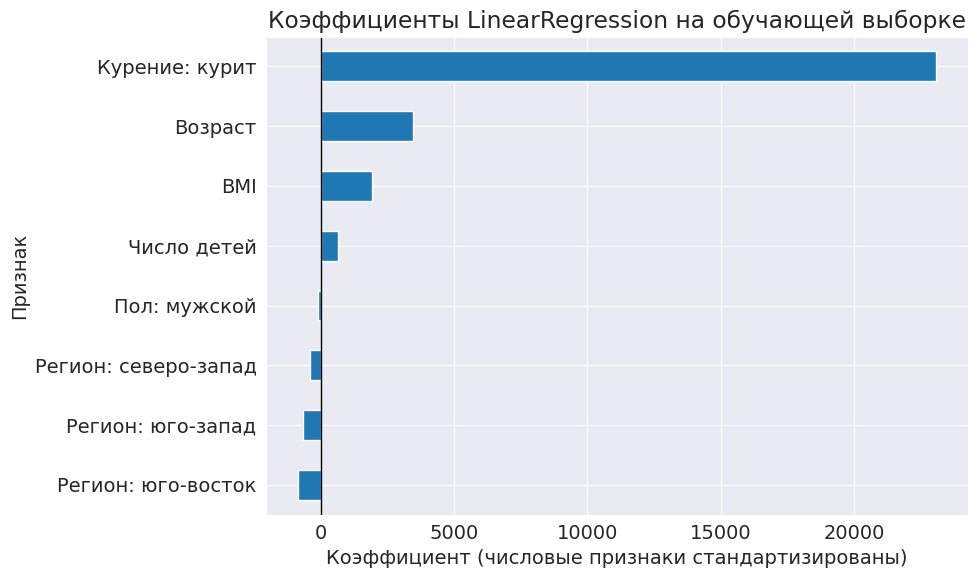

In [294]:
weights_df.sort_values('weight').plot.barh(x='feature', y='weight', legend=False)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Коэффициент (числовые признаки стандартизированы)')
plt.title('Коэффициенты LinearRegression на обучающей выборке')
plt.tight_layout()
plt.ylabel('Признак')
plt.yticks(range(len(weights_df)), weights_df.sort_values('weight').feature.map(feature_labels))
plt.tight_layout()

In [295]:
from sklearn.inspection import permutation_importance

In [296]:
importance_values = []

In [297]:
for train_index, valid_index in cv.split(inputs_train):
    model = clone(best_model)
    model.fit(inputs_train.iloc[train_index], targets_train.iloc[train_index])
    importance = permutation_importance(
        model, inputs_train.iloc[valid_index], targets_train.iloc[valid_index],
        scoring='neg_root_mean_squared_error', n_repeats=10, random_state=42
    )
    importance_values.append(importance.importances)

In [298]:
importance_values = np.concatenate(importance_values, axis=1)

In [299]:
importance_df = pd.DataFrame({
    'feature': input_cols,
    'RMSE_increase': importance_values.mean(axis=1),
    'std': importance_values.std(axis=1)
})
importance_df.sort_values('RMSE_increase', ascending=False).round(3)

,feature,RMSE_increase,std
3,smoker,10357.446,954.554
1,bmi,3077.933,531.223
0,age,2352.459,284.769
2,children,191.273,102.719
5,region,13.910,20.526
4,sex,-2.918,16.106


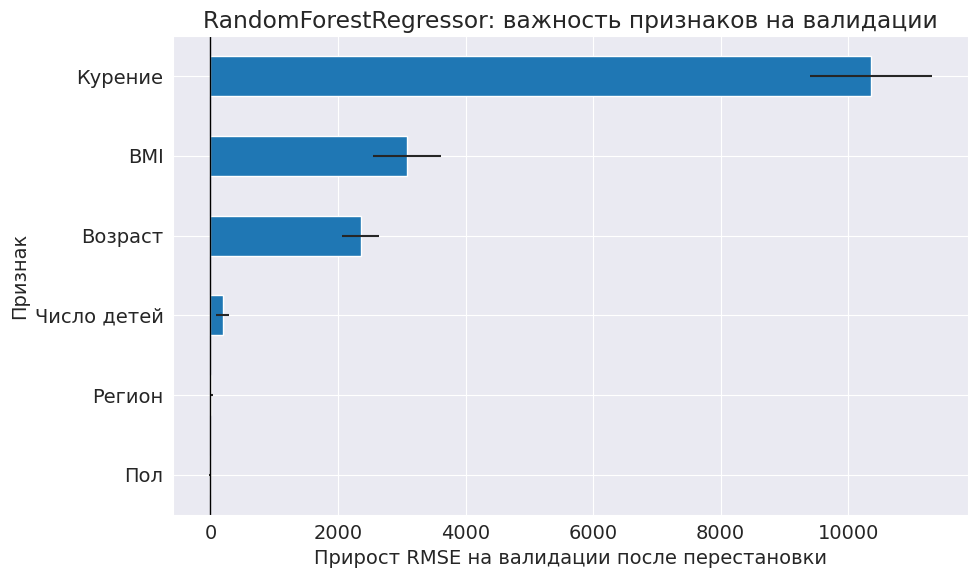

In [300]:
importance_df.sort_values('RMSE_increase').plot.barh(
    x='feature', y='RMSE_increase', xerr='std', legend=False
)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Прирост RMSE на валидации после перестановки')
plt.title('RandomForestRegressor: важность признаков на валидации')
plt.tight_layout()
plt.ylabel('Признак')
plt.yticks(range(len(importance_df)), importance_df.sort_values('RMSE_increase').feature.map(feature_labels))
plt.tight_layout()

In [301]:
from sklearn.metrics import mean_absolute_error, r2_score

In [302]:
predictions_test = best_model.predict(inputs_test)

In [303]:
test_results_df = pd.DataFrame({
    'MAE': [mean_absolute_error(targets_test, predictions_test)],
    'RMSE': [rmse(targets_test, predictions_test)],
    'R2': [r2_score(targets_test, predictions_test)]
}, index=['RandomForestRegressor'])
test_results_df.round(3)

,MAE,RMSE,R2
RandomForestRegressor,2382.145,4206.099,0.904


In [304]:
errors_df = inputs_test.copy()
errors_df['charges'] = targets_test
errors_df['prediction'] = predictions_test
errors_df['error'] = errors_df.charges - errors_df.prediction

In [305]:
errors_df['absolute_error'] = errors_df.error.abs()
errors_df['squared_error'] = errors_df.error ** 2

In [306]:
errors_df.sort_values('absolute_error', ascending=False).head(10).round(2)

,age,bmi,children,smoker,sex,region,charges,prediction,error,absolute_error,squared_error
987,45,27.64,1,no,female,northwest,28340.19,9107.77,19232.42,19232.42,3.698860e+08
637,35,38.10,2,no,female,northeast,24915.05,6752.74,18162.31,18162.31,3.298695e+08
115,60,28.60,0,no,male,northeast,30260.00,13476.43,16783.56,16783.56,2.816879e+08
543,54,47.41,0,yes,female,southeast,63770.43,47312.49,16457.94,16457.94,2.708638e+08
128,32,17.76,2,yes,female,northwest,32734.19,16970.00,15764.18,15764.18,2.485095e+08
819,33,35.53,0,yes,female,northwest,55135.40,39430.26,15705.14,15705.14,2.466516e+08
1230,52,34.48,3,yes,male,northwest,60021.40,44462.19,15559.21,15559.21,2.420891e+08
291,29,29.64,1,no,male,northeast,20277.81,5572.32,14705.49,14705.49,2.162514e+08
573,62,36.86,1,no,female,northeast,31620.00,16982.73,14637.27,14637.27,2.142496e+08
306,28,27.50,2,no,female,southwest,20177.67,5885.97,14291.70,14291.70,2.042528e+08


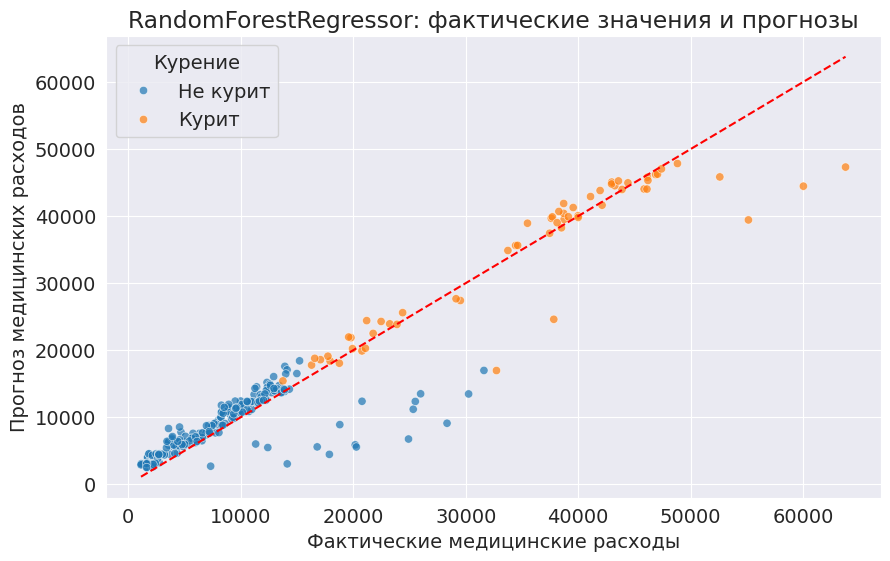

In [307]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=errors_df, x='charges', y='prediction', hue='smoker', alpha=0.7)
limits = [min(errors_df.charges.min(), errors_df.prediction.min()),
          max(errors_df.charges.max(), errors_df.prediction.max())]
plt.plot(limits, limits, 'r--')
plt.xlabel('Фактические медицинские расходы')
plt.ylabel('Прогноз медицинских расходов')
plt.title('RandomForestRegressor: фактические значения и прогнозы')
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles, [category_labels[label] for label in labels], title='Курение')

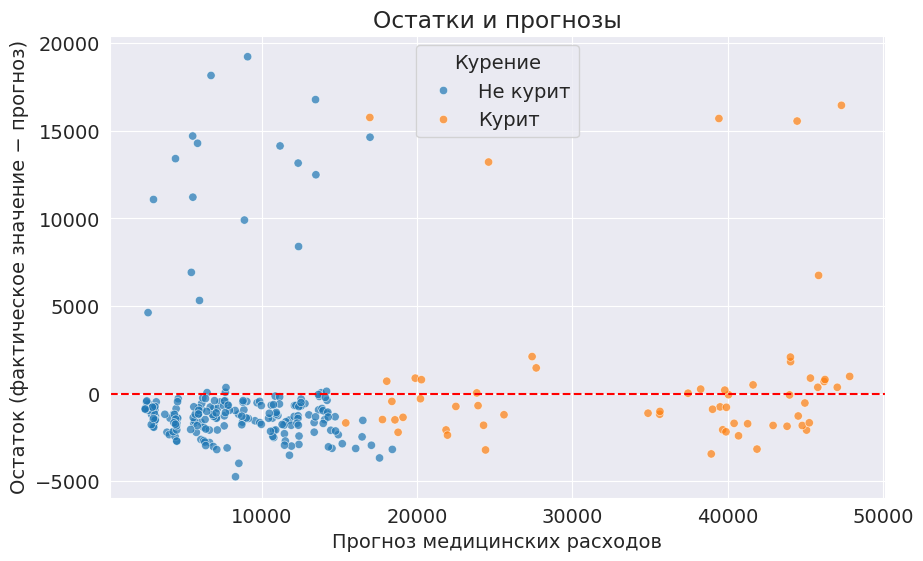

In [308]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=errors_df, x='prediction', y='error', hue='smoker', alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Прогноз медицинских расходов')
plt.ylabel('Остаток (фактическое значение − прогноз)')
plt.title('Остатки и прогнозы')
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles, [category_labels[label] for label in labels], title='Курение')

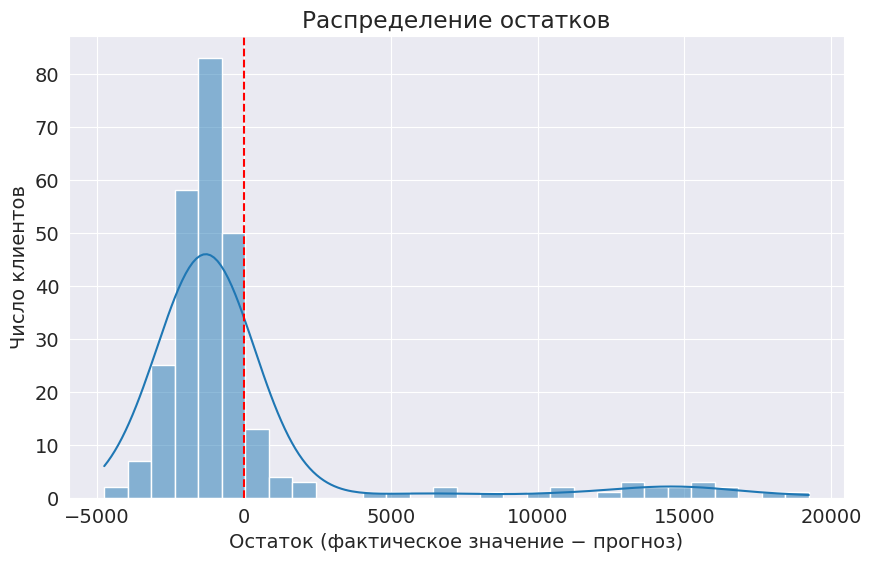

In [309]:
plt.figure(figsize=(10, 6))
sns.histplot(x=errors_df['error'].to_numpy(dtype=float), bins=30, kde=True)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Остаток (фактическое значение − прогноз)')
plt.title('Распределение остатков');
plt.ylabel('Число клиентов');

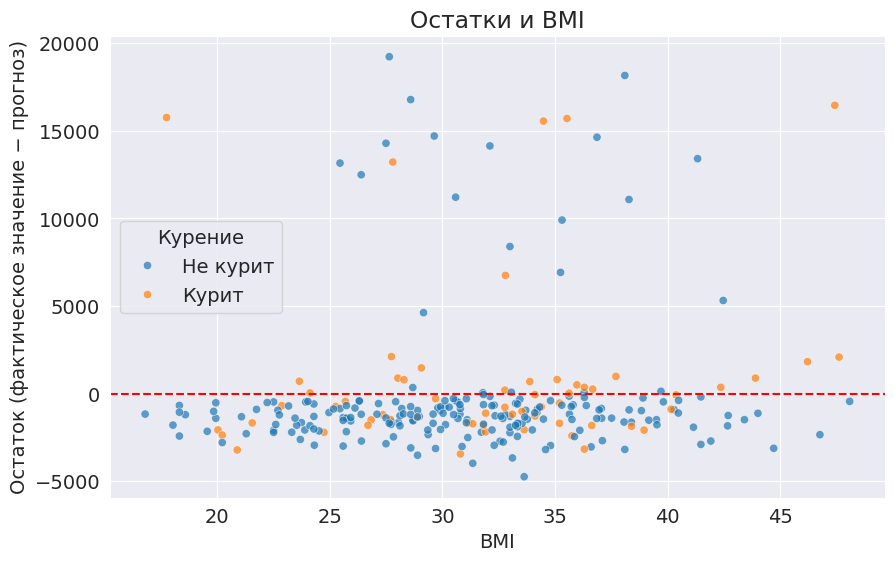

In [310]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=errors_df, x='bmi', y='error', hue='smoker', alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.ylabel('Остаток (фактическое значение − прогноз)')
plt.title('Остатки и BMI');
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles, [category_labels[label] for label in labels], title='Курение');
plt.xlabel('BMI');

In [311]:
group_errors_df = errors_df.groupby('smoker').agg(
    count=('error', 'size'), MAE=('absolute_error', 'mean'),
    MSE=('squared_error', 'mean'), bias=('error', 'mean')
)

In [312]:
group_errors_df['RMSE'] = np.sqrt(group_errors_df.pop('MSE'))
group_errors_df.round(3)

,count,MAE,bias,RMSE
smoker,,,,
no,208,2333.084,-322.262,4034.384
yes,60,2552.224,727.724,4753.593


In [313]:
import joblib

In [314]:
joblib.dump(best_model, 'medical_cost_model.joblib', compress=3)

['medical_cost_model.joblib']

In [315]:
loaded_model = joblib.load('medical_cost_model.joblib')

In [316]:
np.testing.assert_allclose(loaded_model.predict(inputs_test), predictions_test)

In [317]:
new_customer = pd.DataFrame([{
    'age': 35, 'bmi': 27.5, 'children': 1,
    'smoker': 'no', 'sex': 'female', 'region': 'northwest'
}])

In [318]:
loaded_model.predict(new_customer)

array([6147.38731929])